# Figure 1 — Recoil effects during inelastic electron–light interaction

Panels **(c)** and **(d)**: energy-sideband probabilities $P_\ell(\zeta)=|\phi_\ell(\zeta)|^2$ as a function of the
normalized propagation distance $\zeta=\omega z/v$ for a phase-matched electron ($\delta_v=0$) and $g=0.1$.

* **(c)** nonrecoil limit $a\to\infty$: analytical solution $P_\ell=J_\ell^2(2g\zeta)$;
* **(d)** recoil parameter $a=3000$: numerical transfer-matrix propagation (`pinem_recoil.propagate_steps`).

Panels (a) and (b) are schematic illustrations and contain no data.

**Data files** (plain-text CSV, see `data/README.md`): `data/fig1/fig1c_P.csv`, `data/fig1/fig1d_P.csv` (sideband maps,
rows $\ell$, columns $\zeta$) and `data/fig1/fig1_parameters.csv`.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pinem_recoil as pr

DATA = Path("data") / "fig1"
FIGS = Path("figures")
DATA.mkdir(parents=True, exist_ok=True)
FIGS.mkdir(exist_ok=True)

# Set to True to recompute the data even if the data file already exists.
RECOMPUTE = False

## Parameters

In [2]:
g = 0.1            # coupling strength
a = 3000           # recoil parameter, panel (d)
l_max = 150        # sideband truncation |l| <= l_max
zeta_max = 750     # propagation distance
d_zeta = 1         # step length
d_phi = -d_zeta    # field-phase step: phase matching for l = 0 (delta_v = 0)
n_zeta_analytic = 1000   # number of zeta samples for the analytical panel (c)

## Computation (runs only if the data file is missing or `RECOMPUTE = True`)

In [3]:
files = {key: DATA / f"fig1{key}_P.csv" for key in "cd"}
file_par = DATA / "fig1_parameters.csv"
if RECOMPUTE or not all(f.exists() for f in [*files.values(), file_par]):
    # (c) nonrecoil analytical solution
    zeta_c = np.linspace(0, zeta_max - 1, n_zeta_analytic)
    P_c = pr.nonrecoil_analytic(g, l_max, zeta_c) ** 2
    # (d) recoil, transfer-matrix propagation
    zeta_d, phi_d = pr.propagate_steps(a, g, l_max, d_zeta, d_phi, int(zeta_max / d_zeta))
    P_d = np.abs(phi_d) ** 2
    ell = pr.sideband_axis(l_max)
    pr.save_map(files["c"], P_c, zeta_c, ell, "zeta", "ell")
    pr.save_map(files["d"], P_d, zeta_d, ell, "zeta", "ell")
    pr.save_parameters(file_par, [
        ("g", g, "coupling strength (c) and (d)"),
        ("a_d", a, "recoil parameter of panel (d); panel (c): a -> infinity (analytical J_l^2(2 g zeta))"),
        ("l_max", l_max, "sideband truncation |l| <= l_max"),
        ("d_zeta", d_zeta, "propagation step of panel (d)"),
        ("d_phi", d_phi, "field-phase step per propagation step (phase matching)"),
    ])
    print("computed and saved", *files.values(), file_par)

computed and saved data\fig1\fig1c_P.csv data\fig1\fig1d_P.csv data\fig1\fig1_parameters.csv


## Load data and plot

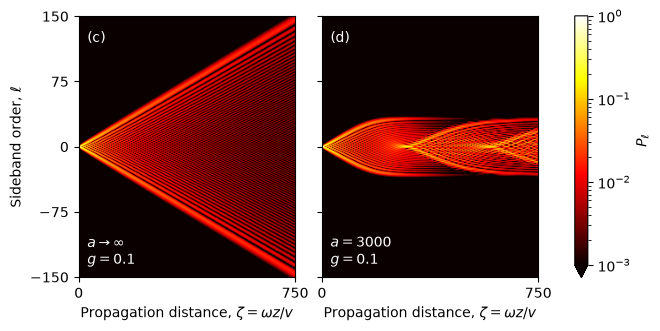

In [4]:
maps = {key: pr.load_map(f) for key, f in files.items()}     # key -> (zeta, ell, P)

cmap = plt.get_cmap("hot").copy()
cmap.set_under(cmap(0.0))
cmap.set_bad(cmap(0.0))
norm = LogNorm(vmin=1e-3, vmax=1)

def extent(zeta, ell):
    dz = zeta[1] - zeta[0]
    return [zeta[0] - dz / 2, zeta[-1] + dz / 2, ell[0] - 0.5, ell[-1] + 0.5]

fig, axs = plt.subplots(1, 2, figsize=(6.5, 3.2), sharey=True, constrained_layout=True)
for ax, key, label, txt in [
    (axs[0], "c", "(c)", r"$a\to\infty$" + "\n" + rf"$g={g}$"),
    (axs[1], "d", "(d)", rf"$a={a}$" + "\n" + rf"$g={g}$"),
]:
    zeta, ell, P = maps[key]
    im = ax.imshow(P, aspect="auto", origin="lower", cmap=cmap, norm=norm, extent=extent(zeta, ell))
    ax.text(0.04, 0.90, label, color="w", transform=ax.transAxes)
    ax.text(0.04, 0.05, txt, color="w", transform=ax.transAxes)
    ax.set_xticks([0, zeta_max])
    ax.set_xlabel(r"Propagation distance, $\zeta=\omega z/v$")
axs[0].set_yticks([-150, -75, 0, 75, 150])
axs[0].set_ylabel(r"Sideband order, $\ell$")
cb = fig.colorbar(im, ax=axs, extend="min")
cb.set_label(r"$P_\ell$")
fig.savefig(FIGS / "fig1.png", dpi=200)
fig.savefig(FIGS / "fig1.pdf")
plt.show()